---
title: Reading netCDF files
authors:
  - alex_dunne
downloads:
  - file: ./beginners_guide.zip
    title: Download the guide (.zip)
thumbnail: https://github.com/21centuryweather/Weather-Change-Cookbook/blob/main/recipes/beginners_guide/section1.png?raw=true
---

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/21centuryweather/Weather-Change-Cookbook/binder-beginners_guide)	­

## Setting Up: Imports & Libraries

It is good practice to start every file with some basic descriptors. This will help future you when looking through files, and others when you share your code.

```
""" 
Script Name
=====================================================
Description: This notebook will help beginner coders open and inspect data

Version History: 22/05/26, written by A.D. & Claude 

Notes:
"""
```

:::{note} Notation shorthand: `#` and `“”`

In a Code cell, whatever is written after a `#` will become a comment, and Python will not read it.
You can also use `“ ”` to write longer text that Python will ignore.
:::

## Imports & Libraries 

Every script o Jupyter notebook starts with importing the libraries you need. Think of this as gathering your tools before starting work.

These are four very common libraries in climate science. I recommend googling each of their names and reading the description about what they are used for. 

In [3]:
import xarray as xr          # NetCDF & multi-dimensional data

:::{note} Library shorthand: `import xarray as xr`

The 'as xr' part creates an alias — instead of typing `xarray.open_dataset()` every time, you just write `xr.open_dataset()`.
:::

In [ ]:
# Download the data, it can take a few minutes
!python download_data.py

## Opening a Single NetCDF File

NetCDF (Network Common Data Form) is the standard file format for climate and atmospheric data. Each file can hold many variables across time, latitude, and longitude.

In [2]:
file_path = ("data/2GMEL_ideal-actual_timeseries.nc")     # path to your file
ds = xr.open_dataset(file_path)                           # open it as a Dataset
ds                                                        # inspect the Dataset

<xarray.Dataset> Size: 9MB
Dimensions:  (time: 389959)
Coordinates:
  * time     (time) datetime64[ns] 3MB 2015-07-31T18:30:00 ... 2025-12-31T11:...
Data variables:
    actual   (time) float64 3MB ...
    ideal    (time) float64 3MB ...

:::{note} `xr.open_dataset()`

Opens a single NetCDF file and returns an xarray Dataset — an object that holds all variables, coordinates, and metadata together.
:::

### What you'll see

When you `print(ds)`, xarray shows you the **Dimensions** (e.g. time, lat, lon), **Coordinates** (the actual values along each dimension), and **Data** variables (the physical quantities stored). 

## Inspect dimensions, coordinates, and attributes

In [3]:
print(ds.dims)        # e.g. {'time': 8760, 'lat': 1, 'lon': 1}
print(ds.time)        # the actual coordinate values
print(ds.attrs)       # global metadata (source, units, author...)
print(ds.data_vars)   # list of variable names

FrozenMappingWarningOnValuesAccess({'time': 389959})
<xarray.DataArray 'time' (time: 389959)> Size: 3MB
array(['2015-07-31T18:30:00.000000000', '2015-07-31T18:40:00.000000000',
       '2015-07-31T18:50:00.000000000', ..., '2025-12-31T11:10:00.000000000',
       '2025-12-31T11:20:00.000000000', '2025-12-31T11:30:00.000000000'],
      shape=(389959,), dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 3MB 2015-07-31T18:30:00 ... 2025-12-31T11:...
Attributes:
    long_name:  time
    comment:    Start time of the corresponding satellite observation period
{}
Data variables:
    actual   (time) float64 3MB ...
    ideal    (time) float64 3MB ...


In our example, we have one dimension – time, and for each time step (every 10 minutes) we have Melbourne’s actual and ideal solar generation. What does that mean? *Ideal* solar generation is how much solar would be generated assuming perfect clear sky conditions, *actual* is the amount that was actually produced on that day (taking into account clouds). 

## Access a single variable

Sometimes, NetCDF datasets hold multiple variables inside. For example, if you’re looking at a dataset for solar, you might have one variable for raw downward solar irradiance, and one for capacity factor. To inspect or plot anything, you have to tell the code what variable you want to look at. In this example, we are inspecting a variable called “ideal”.

In [4]:
# Two equivalent ways to get a single variable as a DataArray:
da = ds["ideal"]   # dictionary-style (preferred)
da = ds.ideal      # attribute-style

print(da)          # inspect the DataArray
print(da.dims)               # its dimensions
print(da.attrs)              # its metadata/units

<xarray.DataArray 'ideal' (time: 389959)> Size: 3MB
[389959 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 3MB 2015-07-31T18:30:00 ... 2025-12-31T11:...
('time',)
{}


:::{note} Dataset vs DataArray: `ds["variable_name"]`

A Dataset (ds) holds multiple variables. Selecting one by name gives you a DataArray (da)— a single variable with its own coordinates and attributes.
:::

## Plot a single variable

This is a very simple netCDF file we are working with. We can inspect a timeseries of each of these variables to see what the difference is between “actual” and “ideal”. Note, most netCDFs that you work with will have time, lat and lon, so `da.plot()` will NOT work for most of these cases.

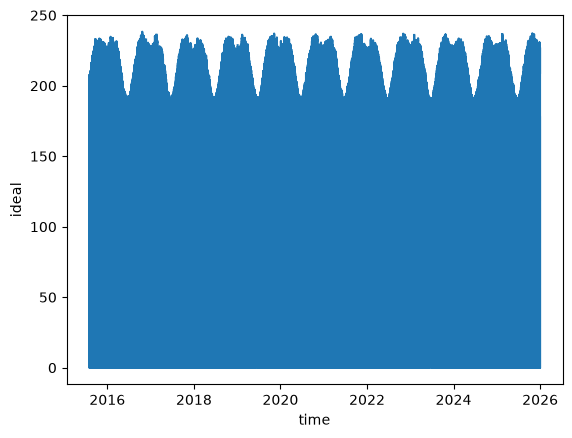

In [5]:
# plot a simple timeseries for all data in the variable we defined above
da.plot()   # very simple plot of a single variable for a time series

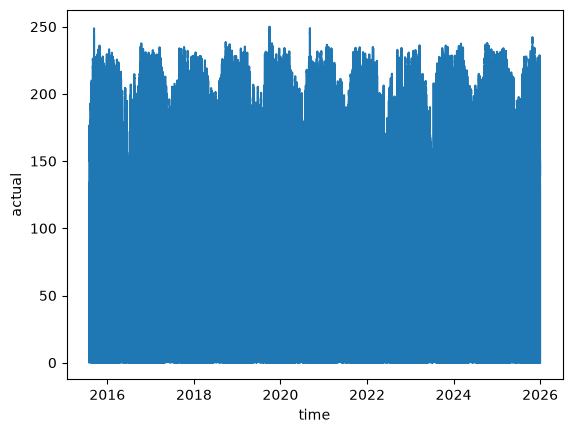

In [6]:
da_actual = ds.actual

da_actual.plot()

## Your turn: repeat the steps using different data

This section includes another netCDF file, this time with different variables. Repeat the steps above to open the file, inspect the dimensions, coordinates and attributes, and plot at least one variable (we suggest you to start with `cloud_type`).

To read more about the dataset, check the [documentation](https://geonetwork.nci.org.au/geonetwork/srv/eng/catalog.search#/metadata/f0134_9465_9618_8960).

**Click on the cells below to check your answers.**

In [6]:
path = "data/IDE00326.202412311940.nc"
ds = xr.open_dataset(path)
ds

<xarray.Dataset> Size: 260MB
Dimensions:                     (time: 1, latitude: 1726, longitude: 2214)
Coordinates:
  * time                        (time) datetime64[ns] 8B 2024-12-31T19:40:00
  * latitude                    (latitude) float32 7kB -44.5 -44.48 ... -10.0
  * longitude                   (longitude) float32 9kB 112.0 112.0 ... 156.3
Data variables:
    crs                         int32 4B ...
    surface_global_irradiance   (time, latitude, longitude) float64 31MB ...
    direct_normal_irradiance    (time, latitude, longitude) float64 31MB ...
    surface_diffuse_irradiance  (time, latitude, longitude) float64 31MB ...
    quality_mask                (time, latitude, longitude) float64 31MB ...
    cloud_type                  (time, latitude, longitude) float32 15MB ...
    cloud_optical_depth         (time, latitude, longitude) float64 31MB ...
    solar_elevation             (time, latitude, longitude) float64 31MB ...
    solar_azimuth               (time, latitude, longitude) float64 31MB ...
    julian_date                 (time, latitude, longitude) float64 31MB ...
Attributes: (12/57)
    Conventions:                      CF-1.7
    Metadata_Conventions:             Unidata Dataset Discovery v1.0
    acknowledgment:                   The following acknowledgement is requir...
    cdm_data_type:                    grid
    comment:                          Solar radiation data derived from satel...
    contributor_name:                 Mines ParisTech; Commonwealth of Austra...
    ...                               ...
    date_created:                     20250325T030425Z
    bias_correction_applied:          1
    bias_correction_applied_meaning:  0: not applied; 1:applied
    quality:                          0
    quality_meaning:                  0: no_known_issues 1: known_issue 
    history:                          heliosat-4; post_process_p1s.py

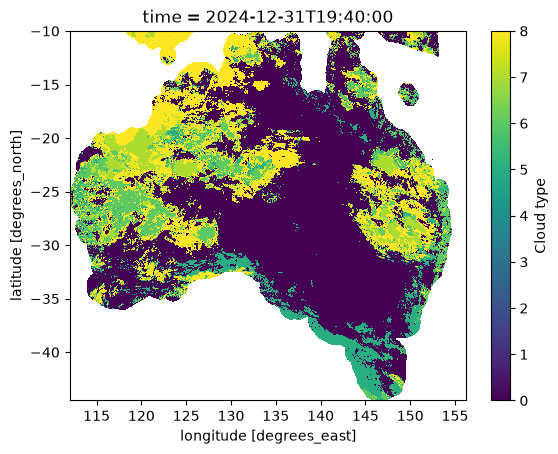

In [7]:
da = ds.cloud_type
da.plot()